# 02 — Otimizadores e função de perda

Backbone fixo: **EfficientNetV2-B0, 224 px, fine-tuning completo** (vencedor de AUC no NB01 e o mais rápido dos modernos). Comparamos, sob o mesmo protocolo:

| Experimento | Otimizador | Scheduler | Loss |
|---|---|---|---|
| `nb01_effv2b0_224_full_adamw` (referência) | AdamW (wd 0,05) | cosine + warmup | BCE ponderada |
| `nb02_effv2b0_adam_plateau` | **Adam** (o do campeão atual) | ReduceLROnPlateau | BCE ponderada |
| `nb02_effv2b0_sgd_nesterov` | SGD Nesterov (lr 0,01, m 0,9) | cosine + warmup | BCE ponderada |
| `nb02_effv2b0_sam_adamw` | **SAM** (ρ 0,05) sobre AdamW | cosine + warmup | BCE ponderada |
| `nb02_effv2b0_adamw_focal` | AdamW | cosine + warmup | **Focal** (γ 2, α 0,6) |

SAM (*Sharpness-Aware Minimization*) busca mínimos "planos", o que tende a generalizar melhor em datasets pequenos — ao custo de 2 passadas por batch. SGD foi incluído porque a literatura recente de detecção em sonar (Liu et al., JMSE 2026) o encontrou geralmente melhor que AdamW.

### Protocolo comum (todos os notebooks)
- **Dados:** 1170 imagens side-scan sonar (Marinha Portuguesa, 2010–2021). Rótulo 1 = contém ≥1 **MILCO** (mine-like contact), 255 imagens (21,8%); 0 = só NOMBO ou fundo.
- **Split de triagem (holdout):** estratificado fixo 70/15/15 (seed 42) → treino 819 · validação 175 · teste 176 (38 minas). Mesmo split para todos os experimentos.
- **Seleção do checkpoint:** melhor AUC na **validação** (early stopping). O **threshold** de decisão também é escolhido na validação — o teste só é usado uma vez.
- **Métricas no teste:** ROC-AUC (principal), PR-AUC, F1/precisão/recall com threshold da validação, F1@0.5 e *F1 oráculo* (threshold escolhido no próprio teste, só para comparar com a metodologia do notebook antigo).
- **Atenção:** com 38 positivos no teste, diferenças < ~0,02 de AUC estão dentro do ruído — por isso os finalistas passam por **validação cruzada 5-fold** (notebook 04).

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
pd.set_option("display.precision", 3); pd.set_option("display.width", 200)
sys.path.insert(0, str(Path.cwd()))
import sonar_harness as h
import analise as A
fila = json.load(open("fila_experimentos.json"))

In [2]:
# ------------------------------------------------------------------
# (Opcional) Re-treinar os experimentos deste notebook.
# Os resultados abaixo já foram gerados pela fila de execução (máquina local, CPU, treino fatiado).
# Em uma máquina com GPU basta trocar RODAR_TREINO para True: o harness treina de ponta a ponta
# (o mesmo código que roda fatiado também roda sem limite de tempo).
# ------------------------------------------------------------------
RODAR_TREINO = False
GRUPO = "NB02"
jobs = [j for j in fila if j.get("group") == GRUPO]
for j in jobs:
    print(f"{j['id']:45s} {j.get('desc','')}")
if RODAR_TREINO:
    import math
    for j in jobs:
        h.train_job(j, deadline=math.inf)

nb02_effv2b0_adam_plateau                     Otimizador Adam (como no baseline) + ReduceLROnPlateau
nb02_effv2b0_sgd_nesterov                     SGD Nesterov momentum 0.9 + cosine (lr 0.01)
nb02_effv2b0_sam_adamw                        SAM (rho 0.05) sobre AdamW + cosine
nb02_effv2b0_adamw_focal                      AdamW + cosine com Focal Loss (gamma 2, alpha 0.6)


## Resultados no teste do holdout

In [3]:
runs = {**A.load_runs("nb02_"), **{k: v for k, v in A.load_runs("nb01_").items() if k in ("nb01_effv2b0_224_full_adamw", "nb01_baseline_mnv2_96_frozen_adam")}}
df = A.tabela(runs)
df

,experimento,backbone,res,treino,otimizador,loss,aug,AUC,PR-AUC,F1 (thr val),Precisão (thr val),Recall (thr val),F1@0.5,F1 oráculo,épocas,treino (min),inferência (ms/img CPU)
0,nb02_effv2b0_sam_adamw,tf_efficientnetv2_b0,224,full,sam+adamw,bce,standard,0.963,0.918,0.841,0.935,0.763,0.828,0.889,25,46.906,15.428
1,nb01_effv2b0_224_full_adamw,tf_efficientnetv2_b0,224,full,adamw,bce,standard,0.957,0.882,0.771,0.844,0.711,0.765,0.818,21,24.502,17.384
2,nb02_effv2b0_adam_plateau,tf_efficientnetv2_b0,224,full,adam,bce,standard,0.957,0.899,0.838,0.861,0.816,0.843,0.875,25,23.933,17.804
3,nb02_effv2b0_sgd_nesterov,tf_efficientnetv2_b0,224,full,sgd,bce,standard,0.951,0.870,0.779,0.769,0.789,0.750,0.795,19,17.807,15.326
4,nb02_effv2b0_adamw_focal,tf_efficientnetv2_b0,224,full,adamw,focal,standard,0.945,0.869,0.753,0.681,0.842,0.753,0.827,16,15.186,18.143
5,nb01_baseline_mnv2_96_frozen_adam,mobilenetv2_100,96,frozen,adam,bce,baseline,0.909,0.805,0.735,0.833,0.658,0.727,0.753,19,0.927,2.333


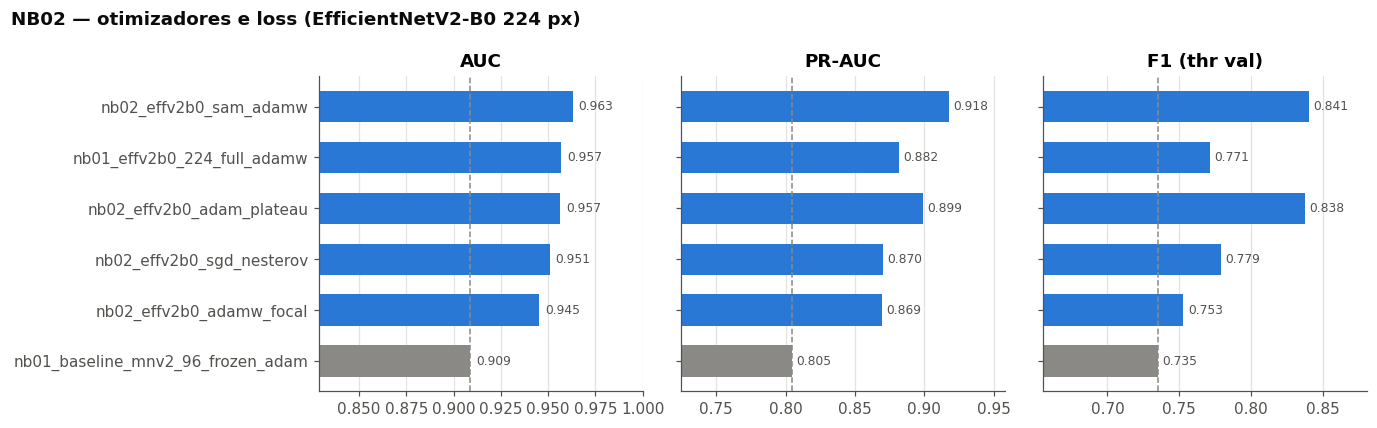

In [4]:
A.barras(df, titulo="NB02 — otimizadores e loss (EfficientNetV2-B0 224 px)", arquivo="nb02_barras.png");

In [5]:
A.tabela(runs, tta=True)[["experimento","AUC","PR-AUC","F1 (thr val)","Precisão (thr val)","Recall (thr val)"]]

,experimento,AUC,PR-AUC,F1 (thr val),Precisão (thr val),Recall (thr val)
0,nb02_effv2b0_adam_plateau,0.962,0.893,0.771,0.844,0.711
1,nb02_effv2b0_sam_adamw,0.961,0.906,0.824,0.933,0.737
2,nb01_effv2b0_224_full_adamw,0.950,0.867,0.795,0.829,0.763
3,nb02_effv2b0_adamw_focal,0.950,0.874,0.810,0.739,0.895
4,nb02_effv2b0_sgd_nesterov,0.940,0.847,0.761,0.818,0.711
5,nb01_baseline_mnv2_96_frozen_adam,0.894,0.788,0.720,0.730,0.711


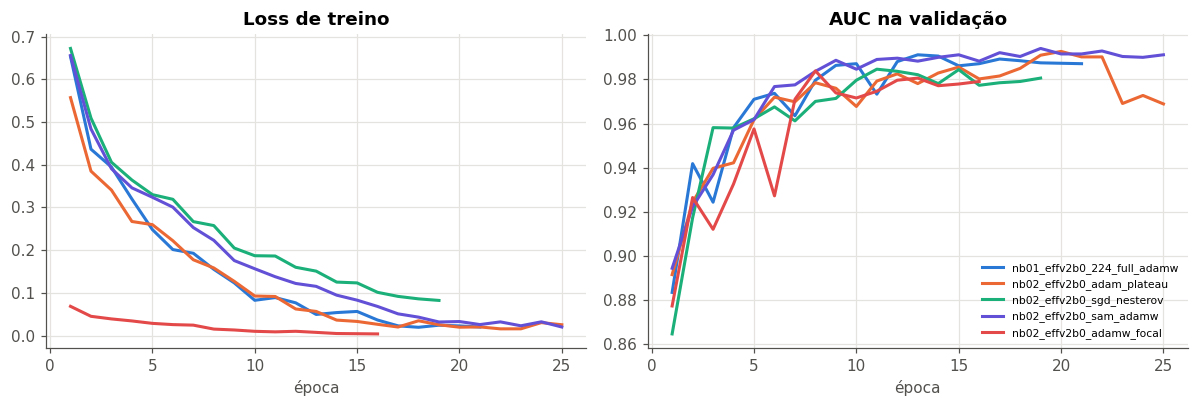

In [6]:
A.curvas_treino(runs, ["nb01_effv2b0_224_full_adamw","nb02_effv2b0_adam_plateau","nb02_effv2b0_sgd_nesterov","nb02_effv2b0_sam_adamw","nb02_effv2b0_adamw_focal"], arquivo="nb02_curvas.png");

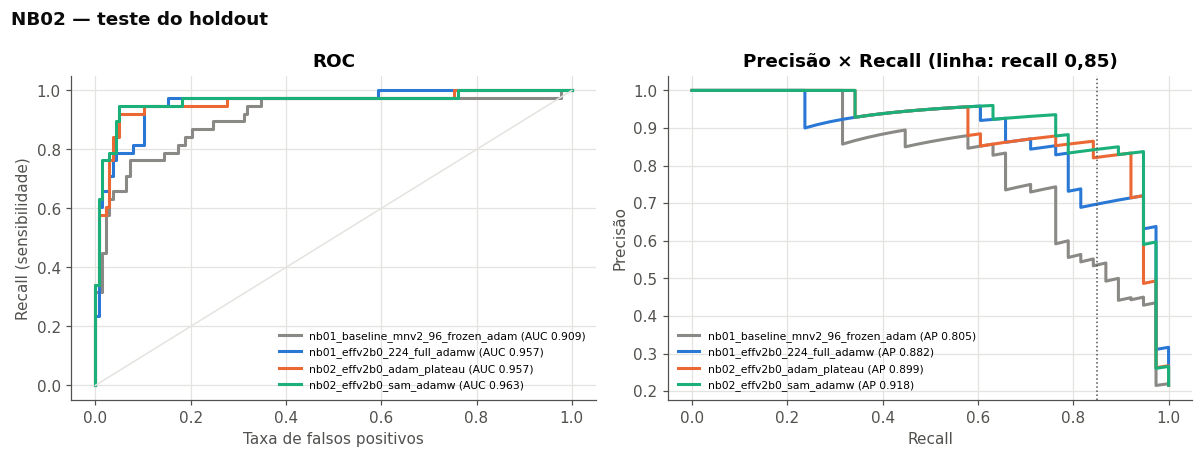

In [7]:
A.roc_pr(["nb01_baseline_mnv2_96_frozen_adam","nb01_effv2b0_224_full_adamw","nb02_effv2b0_adam_plateau","nb02_effv2b0_sam_adamw"],
         titulo="NB02 — teste do holdout", arquivo="nb02_roc_pr.png");

## Leitura
- **SAM + AdamW** foi o melhor do grupo em AUC e, principalmente, em **PR-AUC (≈0,92)** — a métrica mais informativa com classes desbalanceadas.
- **Adam com ReduceLROnPlateau** (o otimizador do campeão atual) também funciona bem com o novo backbone: o ganho grande veio do backbone/resolução/fine-tuning, não da troca de otimizador.
- SGD Nesterov ficou no mesmo patamar do AdamW; Focal Loss não trouxe ganho sobre a BCE ponderada.
- **Na validação cruzada (notebook 04)** a vantagem do SAM encolhe: AUC 0,941 vs 0,934 do Adam e PR-AUC igual (0,878) — ganho pequeno, ao custo de 2× o tempo de treino.